# Phase 1 — pivot reversal statistics across the LS universe

Groundwork for the **`trend_pivot`** strategy's mean-reversion overlay. A slow
cross-sectional trend book sets the direction (long top quintile / short bottom);
this overlay times entries *within* each leg by fading toward anticipated JASON
pivots — **accumulate longs into anticipated low pivots, fade shorts into
anticipated high pivots**. To do that *before* a pivot confirms (JASON pivots are
lagged), we need the empirical priors:

1. **Where** reversals sit in z-space — `z_dn` at bottoms, `z_up` at tops — and the
   **time between pivots**, pooled vs per-name.
2. **Whether stretch is predictive** — does high `z_dn` precede up-reversion and
   high `z_up` precede down-reversion? Vol-normalized forward returns by z-decile.
   *This is the edge test; no edge here → no overlay.*
3. **Stability** — are the thresholds steady enough (expanding window) to use causally.

Universe: **LS-union ∩ lake** at **1h**, names with ≥1.5y / ≥8760 bars.
Signal: JASON's shipped per-bar `z_up` / `z_dn` (`compute_jason_vectorized`) — the
same feature the live overlay will read. Pivots are labeled with
`research.jason.pivots` (the individual-pivot extractor).

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

REPO_ROOT = Path.cwd()
while not (REPO_ROOT / "src").is_dir() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (13, 4.5), "figure.dpi": 110, "axes.grid": True,
    "grid.alpha": 0.25, "axes.edgecolor": "#888",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})

from src.data.query import get
from src.signals.jason import compute_jason_vectorized
from research.jason.pivots import pivot_importance, significant_pivots, zigzag, waves
from scripts.ls_bot import UNIVERSE as LS_UNIVERSE, CLARITY
# re-assert inline (ls_bot import forces matplotlib.use("Agg")):
%matplotlib inline

TF = "1h"
LOOKBACK, N_PIVOTS, MIN_DAYS, Q = 7, 5, 1, 0.50
BARS_PER_YEAR = 365.0 * 24.0
HORIZONS = [12, 24, 48, 96, 168]          # forward horizons in bars (0.5,1,2,4,7d)
MIN_BARS, MIN_YEARS = 8760, 1.5

candidates = list(dict.fromkeys(LS_UNIVERSE + CLARITY))
print(f"LS-union candidates: {len(candidates)}")

LS-union candidates: 51


## 1 — Universe resolution (LS-union ∩ lake)

Keep only names the lake actually carries at 1h with enough history for stable
pivot statistics (≥1.5y, ≥8760 bars). The rest — mostly equity/metal perps absent
from the crypto lake, plus very new listings — drop out here.

In [2]:
data = {}
skipped = []
for t in candidates:
    df = get("perps", "binance", t.lower(), "bars", TF, start="2021-01-01")
    if df.empty or len(df) < MIN_BARS or (df.index[-1] - df.index[0]).days / 365.25 < MIN_YEARS:
        skipped.append(t); continue
    data[t] = df
UNIVERSE = list(data)
print(f"kept {len(UNIVERSE)} names:\n  {UNIVERSE}")
print(f"\nskipped {len(skipped)}: {skipped}")

2026-07-24 15:10:53,459 WARNING  query | no data for perps/binance/ccusdt/bars (stage=auto); returning empty frame


2026-07-24 15:10:53,567 WARNING  query | no data for perps/binance/vvvusdt/bars (stage=auto); returning empty frame


2026-07-24 15:10:53,574 WARNING  query | no data for perps/binance/billusdt/bars (stage=auto); returning empty frame


2026-07-24 15:10:53,575 WARNING  query | no data for perps/binance/magmausdt/bars (stage=auto); returning empty frame


2026-07-24 15:10:53,586 WARNING  query | no data for perps/binance/aerousdt/bars (stage=auto); returning empty frame


...

2026-07-24 15:10:53,599 WARNING  query | no data for perps/binance/nvdausdt/bars (stage=auto); returning empty frame


2026-07-24 15:10:53,601 WARNING  query | no data for perps/binance/aaplusdt/bars (stage=auto); returning empty frame


2026-07-24 15:10:53,602 WARNING  query | no data for perps/binance/tslausdt/bars (stage=auto); returning empty frame


2026-07-24 15:10:53,603 WARNING  query | no data for perps/binance/skhynixusdt/bars (stage=auto); returning empty frame


kept 29 names:
  ['COMPUSDT', 'ZECUSDT', 'XRPUSDT', 'BTCUSDT', 'ETHUSDT', 'SOLUSDT', 'AAVEUSDT', 'BCHUSDT', 'BNBUSDT', 'NEARUSDT', 'ICPUSDT', 'UNIUSDT', 'PENDLEUSDT', 'RUNEUSDT', 'LDOUSDT', 'JTOUSDT', 'POLUSDT', 'JUPUSDT', 'TAOUSDT', 'INJUSDT', 'ENAUSDT', 'ONDOUSDT', 'ETHFIUSDT', 'HBARUSDT', 'RAYUSDT', 'CAKEUSDT', 'XLMUSDT', 'ADAUSDT', 'LINKUSDT']

skipped 22: ['CCUSDT', 'PAXGUSDT', 'SKYUSDT', 'VVVUSDT', 'HYPEUSDT', 'BILLUSDT', 'MAGMAUSDT', 'GENIUSUSDT', 'AEROUSDT', 'PARTIUSDT', 'BTWUSDT', 'CLUSDT', 'XAGUSDT', 'GOOGLUSDT', 'METAUSDT', 'AMZNUSDT', 'MSFTUSDT', 'NVDAUSDT', 'AAPLUSDT', 'TSLAUSDT', 'SKHYNIXUSDT', 'PUMPUSDT']


## 2 — Extract per-name pivots, z-scores and forward returns

For each name: JASON `z_up`/`z_dn` per bar, causal ambient vol, vol-normalized
forward returns at each horizon, and the significant-pivot zig-zag (to label
bottoms/tops and measure time between pivots). Everything is pooled into three
frames: `bars` (per-bar signal + forward returns), `atpiv` (z at confirmed
pivots), `gaps` (time between consecutive pivots).

In [3]:
from research.jason.pivots import ambient_vol

bars_rows, atpiv_rows, gap_rows, wave_rows = [], [], [], []
for t, ohlc in data.items():
    feat = compute_jason_vectorized(ohlc.copy(), t, TF,
                                    lookback=LOOKBACK, n_pivots=N_PIVOTS, min_days=MIN_DAYS)
    close = ohlc["close"].reindex(feat.index)
    logc = np.log(close.to_numpy(float))
    sig = pd.Series(ambient_vol(ohlc, LOOKBACK, BARS_PER_YEAR), index=ohlc.index).reindex(feat.index).to_numpy()

    b = pd.DataFrame({"name": t, "z_up": feat["z_up"].to_numpy(), "z_dn": feat["z_dn"].to_numpy()},
                     index=feat.index)
    for H in HORIZONS:                     # vol-normalized forward log-return over H bars
        fwd = np.concatenate([logc[H:] - logc[:-H], np.full(H, np.nan)])
        b[f"fwd{H}"] = fwd / (sig * np.sqrt(H / BARS_PER_YEAR))
    lt = np.log(ohlc["close"]) - np.log(ohlc["close"].shift(24 * 28))   # 28d LT-trend (carrier proxy)
    b["trend"] = np.sign(lt.reindex(feat.index).to_numpy())
    bars_rows.append(b)

    piv = pivot_importance(ohlc, TF, LOOKBACK, N_PIVOTS, MIN_DAYS)
    ev, _, _ = significant_pivots(piv, ohlc, Q)
    seq = zigzag(ev)
    fidx = set(feat.index)
    for e in seq:
        if e[4] not in fidx:
            continue
        side = "top" if e[1] == "H" else "bottom"
        z = feat.at[e[4], "z_up"] if side == "top" else feat.at[e[4], "z_dn"]
        atpiv_rows.append({"name": t, "side": side, "z": float(z)})
    for a, c2 in zip(seq, seq[1:]):        # time between consecutive turning points
        gap_rows.append({"name": t, "to_side": "top" if c2[1] == "H" else "bottom",
                         "gap_days": (c2[0] - a[0]) / 24.0})
    w = waves(seq, ohlc, LOOKBACK, BARS_PER_YEAR)
    w["name"] = t
    wave_rows.append(w)

bars = pd.concat(bars_rows)
atpiv = pd.DataFrame(atpiv_rows)
gaps = pd.DataFrame(gap_rows)
wv = pd.concat(wave_rows, ignore_index=True)
print(f"pooled bars: {len(bars):,}  |  confirmed pivots: {len(atpiv):,}  |  waves: {len(wv):,}")

Computing JASON for COMPUSDT:   0%|          | 0/48414 [00:00<?, ?it/s]

Computing JASON for COMPUSDT:   0%|          | 1/48414 [00:05<70:56:23,  5.28s/it]

Computing JASON for COMPUSDT:   9%|▉         | 4566/48414 [00:05<00:36, 1203.85it/s]

Computing JASON for COMPUSDT:  18%|█▊        | 8793/48414 [00:05<00:14, 2694.54it/s]

Computing JASON for COMPUSDT:  28%|██▊       | 13428/48414 [00:05<00:07, 4846.74it/s]

...

Computing JASON for LINKUSDT:  67%|██████▋   | 32488/48414 [00:00<00:00, 44680.68it/s]

Computing JASON for LINKUSDT:  76%|███████▋  | 37021/48414 [00:00<00:00, 44883.46it/s]

Computing JASON for LINKUSDT:  86%|████████▌ | 41511/48414 [00:00<00:00, 44812.83it/s]

Computing JASON for LINKUSDT:  95%|█████████▌| 46165/48414 [00:01<00:00, 45339.70it/s]

pooled bars: 1,118,965  |  confirmed pivots: 137,705  |  waves: 137,746


## 3 — Where reversals sit in z-space (pooled vs per-name)

`z_dn` at confirmed **bottoms** and `z_up` at confirmed **tops**. If the per-name
medians cluster tightly, one pooled threshold serves the whole book; if they
scatter, the overlay needs per-name calibration. The dashed line is the pooled
median.

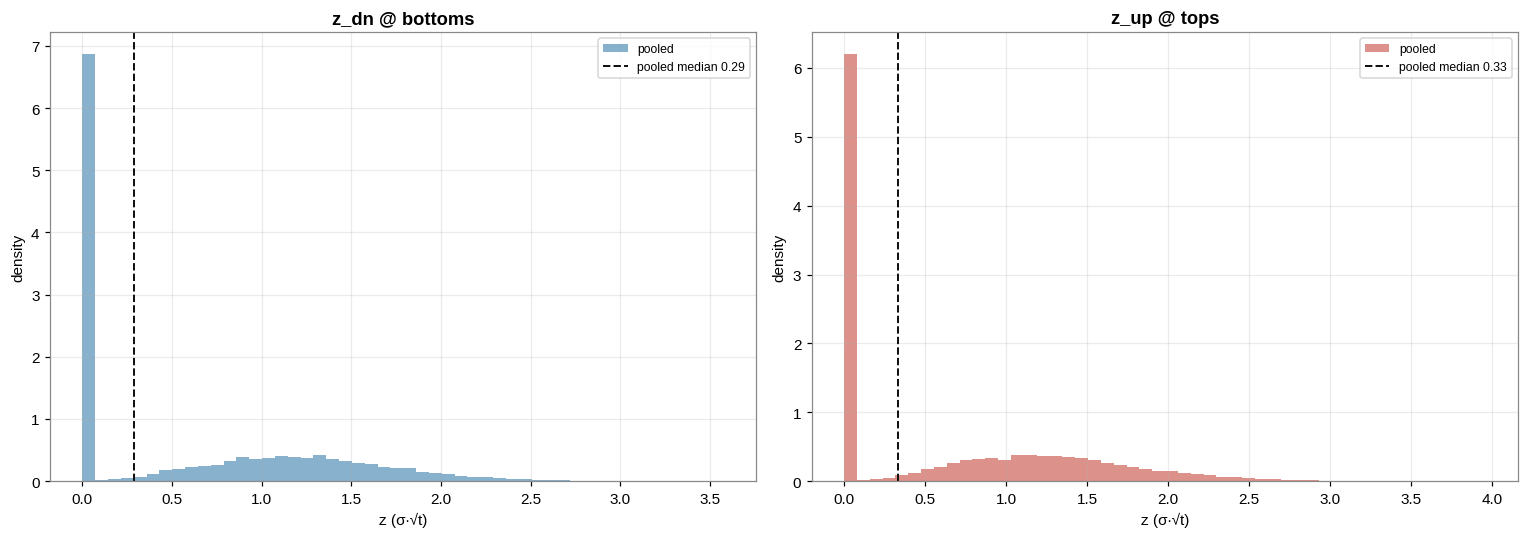

       z_dn@bottom (per-name median)  z_up@top (per-name median)
count                         29.000                      29.000
mean                           1.126                       1.153
std                            0.316                       0.321
min                            0.000                       0.000
25%                            1.160                       1.200
50%                            1.210                       1.230
75%                            1.240                       1.260
max                            1.310                       1.310

cross-name spread (p90-p10):  bottoms 0.15   tops 0.11


In [4]:
bottoms = atpiv[atpiv.side == "bottom"]
tops = atpiv[atpiv.side == "top"]
per_name_bot = bottoms.groupby("name")["z"].median().sort_values()
per_name_top = tops.groupby("name")["z"].median().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, s, lab, col, pn in [(axes[0], bottoms.z, "z_dn @ bottoms", "#2471a3", per_name_bot),
                             (axes[1], tops.z, "z_up @ tops", "#c0392b", per_name_top)]:
    ax.hist(s, bins=50, color=col, alpha=0.55, density=True, label="pooled")
    ax.axvline(s.median(), color="#111", ls="--", lw=1.3, label=f"pooled median {s.median():.2f}")
    ax.set_title(lab); ax.set_xlabel("z (σ·√t)"); ax.set_ylabel("density"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(REPO_ROOT / "pivot_universe_atpivot_z.png", bbox_inches="tight"); plt.show()

spread = pd.DataFrame({
    "z_dn@bottom (per-name median)": per_name_bot.describe(),
    "z_up@top (per-name median)": per_name_top.describe(),
}).round(3)
print(spread.to_string())
print(f"\ncross-name spread (p90-p10):  bottoms {per_name_bot.quantile(.9)-per_name_bot.quantile(.1):.2f}"
      f"   tops {per_name_top.quantile(.9)-per_name_top.quantile(.1):.2f}")

## 4 — Time between pivots

How long a swing runs before the opposite pivot forms — the prior for the
overlay's time-gate (don't start scaling too early into a fresh move).

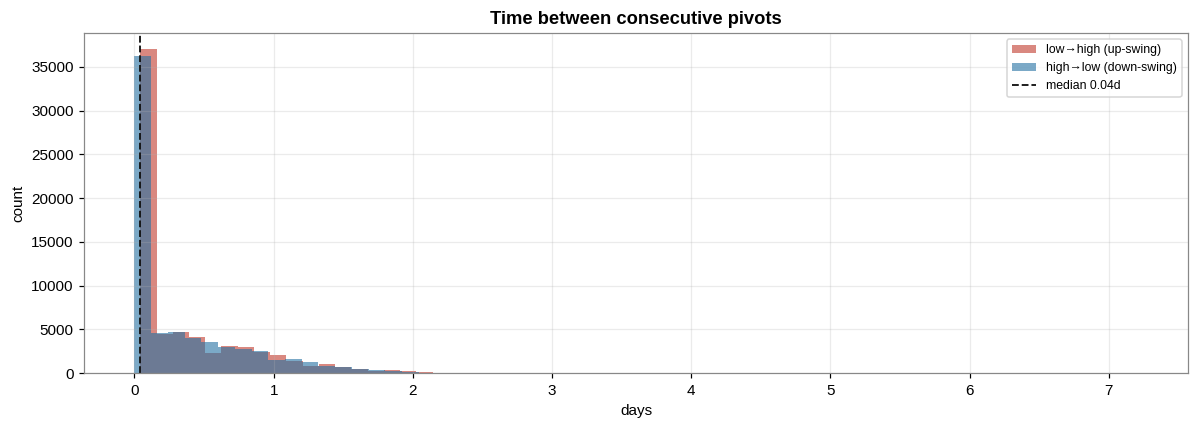

         mean   p50   p90
to_side                  
bottom   0.32  0.04  1.00
top      0.36  0.08  1.04


In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(gaps[gaps.to_side == "top"].gap_days, bins=60, color="#c0392b", alpha=0.6, label="low→high (up-swing)")
ax.hist(gaps[gaps.to_side == "bottom"].gap_days, bins=60, color="#2471a3", alpha=0.6, label="high→low (down-swing)")
ax.axvline(gaps.gap_days.median(), color="#111", ls="--", lw=1.2, label=f"median {gaps.gap_days.median():.2f}d")
ax.set_title("Time between consecutive pivots"); ax.set_xlabel("days"); ax.set_ylabel("count")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print(gaps.groupby("to_side")["gap_days"]
      .agg(mean="mean", p50="median", p90=lambda s: s.quantile(0.9)).round(2).to_string())

## 5 — The edge test: does stretch precede reversion?

The overlay's whole premise. Bucket every bar by z-decile and measure the mean
**vol-normalized forward return** at each horizon:

- **Accumulation (longs):** sort by `z_dn` (oversold vs the high pivot). If the
  edge is real, forward return should **rise** with `z_dn` (deeper drop → stronger
  bounce).
- **Fade (shorts):** sort by `z_up` (overbought vs the low pivot). Forward return
  should **fall** with `z_up` (higher stretch → stronger drop).

Monotonic, correctly-signed curves = a tradable reversion signal. Flat/wrong-signed
= no overlay (a clean null).

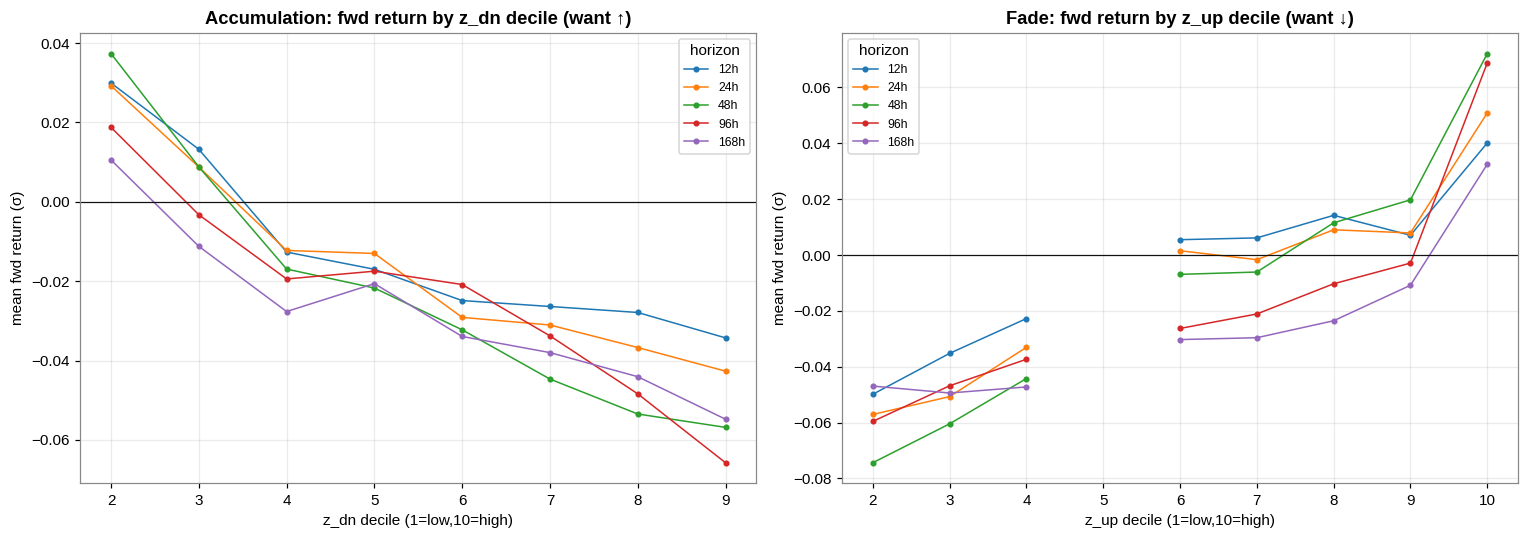

Spearman corr of stretch vs forward return  (accum wants z_dn>0, fade wants z_up<0)
      corr(z_dn,fwd)  corr(z_up,fwd)
12h           0.0128         -0.0095
24h           0.0093         -0.0071
48h          -0.0056          0.0110
96h          -0.0064          0.0010
168h         -0.0103         -0.0022


In [6]:
def decile_curve(signal_col, horizon):
    d = bars[[signal_col, f"fwd{horizon}"]].dropna()
    dec = pd.qcut(d[signal_col], 10, labels=False, duplicates="drop")
    return d.groupby(dec)[f"fwd{horizon}"].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, title in [(axes[0], "z_dn", "Accumulation: fwd return by z_dn decile (want ↑)"),
                       (axes[1], "z_up", "Fade: fwd return by z_up decile (want ↓)")]:
    for H in HORIZONS:
        c = decile_curve(col, H)
        ax.plot(c.index + 1, c.values, marker="o", ms=3, lw=1, label=f"{H}h")
    ax.axhline(0, color="#111", lw=0.8)
    ax.set_title(title); ax.set_xlabel(f"{col} decile (1=low,10=high)")
    ax.set_ylabel("mean fwd return (σ)"); ax.legend(fontsize=8, title="horizon")
plt.tight_layout(); plt.savefig(REPO_ROOT / "pivot_universe_edge.png", bbox_inches="tight"); plt.show()

from scipy.stats import spearmanr
edge = {}
for H in HORIZONS:
    d = bars[["z_dn", "z_up", f"fwd{H}"]].dropna()
    edge[f"{H}h"] = {
        "corr(z_dn,fwd)": round(spearmanr(d.z_dn, d[f"fwd{H}"]).correlation, 4),
        "corr(z_up,fwd)": round(spearmanr(d.z_up, d[f"fwd{H}"]).correlation, 4),
    }
edge_df = pd.DataFrame(edge).T
print("Spearman corr of stretch vs forward return  (accum wants z_dn>0, fade wants z_up<0)")
print(edge_df.to_string())

## 5b — The edge test, done for the actual design: **trend-conditioned**

Section 5 pools all bars, but the strategy never fades unconditionally — it only
**accumulates dips inside uptrends** and **fades rallies inside downtrends**. A
pooled null can hide this: oversold in a *downtrend* tends to keep falling
(continuation) while oversold in an *uptrend* bounces (dip-buy) — the two cancel
when pooled. Split by the LT-trend sign (28d) — the carrier's direction — and test
only the aligned cells:

- **Uptrend → `corr(z_dn, fwd)`** should be **> 0** (buy the dip works).
- **Downtrend → `corr(z_up, fwd)`** should be **< 0** (fade the rally works).

The two off-diagonal cells (counter-aligned) are shown for contrast.

Trend-conditioned Spearman corr (aligned cells are the top two):
      UP: z_dn→fwd (dip-buy, want>0)  DN: z_up→fwd (fade, want<0)  UP: z_up→fwd (contra)  DN: z_dn→fwd (contra)
12h                           0.0050                      -0.0124                -0.0077                 0.0209
24h                           0.0003                      -0.0102                -0.0055                 0.0195
48h                          -0.0168                       0.0008                 0.0186                 0.0087
96h                          -0.0147                      -0.0202                 0.0182                 0.0074
168h                         -0.0114                      -0.0228                 0.0072                 0.0017


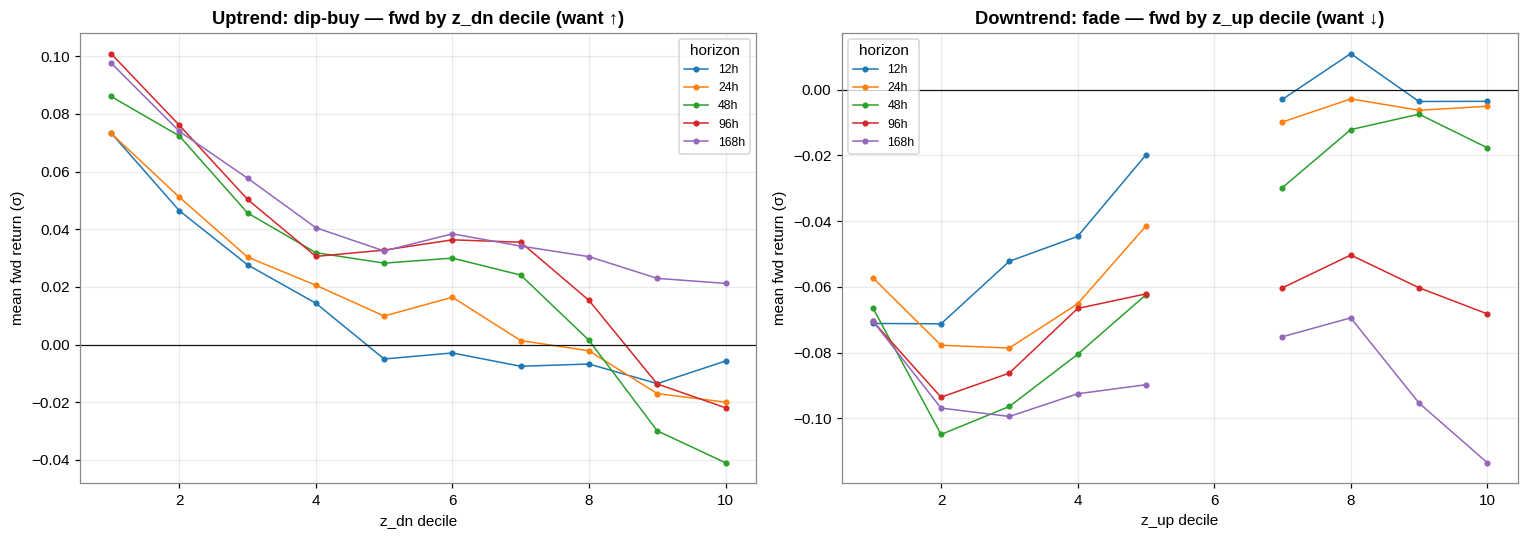

In [7]:
def cond_corr(H):
    d = bars.dropna(subset=[f"fwd{H}", "trend"])
    up, dn = d[d["trend"] > 0], d[d["trend"] < 0]
    return {
        "UP: z_dn→fwd (dip-buy, want>0)": spearmanr(up.z_dn, up[f"fwd{H}"]).correlation,
        "DN: z_up→fwd (fade, want<0)":    spearmanr(dn.z_up, dn[f"fwd{H}"]).correlation,
        "UP: z_up→fwd (contra)":          spearmanr(up.z_up, up[f"fwd{H}"]).correlation,
        "DN: z_dn→fwd (contra)":          spearmanr(dn.z_dn, dn[f"fwd{H}"]).correlation,
    }
cond = pd.DataFrame({f"{H}h": cond_corr(H) for H in HORIZONS}).T.round(4)
print("Trend-conditioned Spearman corr (aligned cells are the top two):")
print(cond.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
d24 = bars.dropna(subset=["fwd24", "trend"])
up, dn = d24[d24["trend"] > 0], d24[d24["trend"] < 0]
for ax, sub, col, title, want in [
    (axes[0], up, "z_dn", "Uptrend: dip-buy — fwd by z_dn decile (want ↑)", "↑"),
    (axes[1], dn, "z_up", "Downtrend: fade — fwd by z_up decile (want ↓)", "↓")]:
    for H in HORIZONS:
        s = sub[[col, f"fwd{H}"]].dropna()
        c = s.groupby(pd.qcut(s[col], 10, labels=False, duplicates="drop"))[f"fwd{H}"].mean()
        ax.plot(c.index + 1, c.values, marker="o", ms=3, lw=1, label=f"{H}h")
    ax.axhline(0, color="#111", lw=0.8); ax.set_title(title)
    ax.set_xlabel(f"{col} decile"); ax.set_ylabel("mean fwd return (σ)"); ax.legend(fontsize=8, title="horizon")
plt.tight_layout(); plt.savefig(REPO_ROOT / "pivot_universe_edge_conditioned.png", bbox_inches="tight"); plt.show()

## 6 — Stability across time

The edge and thresholds are only usable causally if they hold out-of-sample. Two
checks: (a) the sign of the reversion edge per calendar year; (b) the expanding-
window z-threshold (p80 of `z_dn`/`z_up`) — if it plateaus, a causal expanding
estimate ≈ the full-sample value the descriptive sections used.

Reversion edge by year (horizon=48h):
      corr(z_dn,fwd)  corr(z_up,fwd)         n
2021           0.029          -0.019  144179.0
2022          -0.003           0.035  158975.0
2023          -0.011           0.006  171696.0
2024          -0.054           0.057  231060.0
2025           0.027          -0.019  245280.0
2026           0.032          -0.041  132648.0


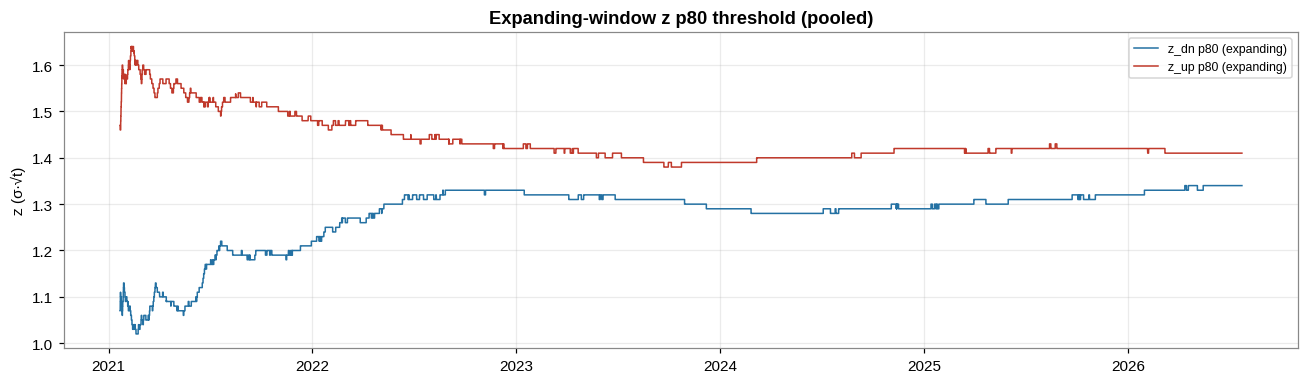

In [8]:
H0 = 48   # anchor horizon (2d)
by_year = {}
b2 = bars.dropna(subset=[f"fwd{H0}"]).copy()
b2["year"] = b2.index.year
for y, g in b2.groupby("year"):
    if len(g) < 2000: continue
    by_year[y] = {"corr(z_dn,fwd)": round(spearmanr(g.z_dn, g[f"fwd{H0}"]).correlation, 3),
                  "corr(z_up,fwd)": round(spearmanr(g.z_up, g[f"fwd{H0}"]).correlation, 3),
                  "n": len(g)}
year_df = pd.DataFrame(by_year).T
print(f"Reversion edge by year (horizon={H0}h):")
print(year_df.to_string())

zseries = bars.sort_index()
exp_dn = zseries["z_dn"].expanding(min_periods=5000).quantile(0.80)
exp_up = zseries["z_up"].expanding(min_periods=5000).quantile(0.80)
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(exp_dn.index, exp_dn.values, color="#2471a3", lw=1, label="z_dn p80 (expanding)")
ax.plot(exp_up.index, exp_up.values, color="#c0392b", lw=1, label="z_up p80 (expanding)")
ax.set_title("Expanding-window z p80 threshold (pooled)"); ax.set_ylabel("z (σ·√t)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 7 — Threshold artifact for Phase 2

Persist what the overlay needs: pooled and per-name z quantiles (the stretch
triggers), at-pivot z medians (reversal anchors), median time-to-pivot (the
time-gate), and the edge summary. Written to
`research/jason/pivot_universe_thresholds.json`.

In [9]:
qs = [0.5, 0.6, 0.7, 0.8, 0.9]

def quantiles(s):
    return {f"p{int(q*100)}": round(float(s.quantile(q)), 4) for q in qs}

artifact = {
    "meta": {"universe": UNIVERSE, "tf": TF, "lookback": LOOKBACK, "n_pivots": N_PIVOTS,
             "min_days": MIN_DAYS, "q_significance": Q, "horizons_bars": HORIZONS,
             "n_bars": int(len(bars)), "n_pivots_labeled": int(len(atpiv))},
    "pooled": {
        "z_dn_quantiles": quantiles(bars["z_dn"].dropna()),
        "z_up_quantiles": quantiles(bars["z_up"].dropna()),
        "z_dn_at_bottoms_median": round(float(bottoms.z.median()), 4),
        "z_up_at_tops_median": round(float(tops.z.median()), 4),
        "gap_days_median": round(float(gaps.gap_days.median()), 3),
        "edge_spearman": edge,
    },
    "per_name": {
        t: {
            "z_dn_quantiles": quantiles(bars[bars.name == t]["z_dn"].dropna()),
            "z_up_quantiles": quantiles(bars[bars.name == t]["z_up"].dropna()),
            "z_dn_at_bottoms_median": round(float(per_name_bot.get(t, np.nan)), 4),
            "z_up_at_tops_median": round(float(per_name_top.get(t, np.nan)), 4),
        } for t in UNIVERSE
    },
}
out_path = REPO_ROOT / "research" / "jason" / "pivot_universe_thresholds.json"
out_path.write_text(json.dumps(artifact, indent=2))
print(f"wrote {out_path}")
print(json.dumps(artifact["pooled"], indent=2))

wrote /home/sam.ahou/projects/operator/research/jason/pivot_universe_thresholds.json
{
  "z_dn_quantiles": {
    "p50": 0.87,
    "p60": 1.0,
    "p70": 1.16,
    "p80": 1.34,
    "p90": 1.6
  },
  "z_up_quantiles": {
    "p50": 0.9,
    "p60": 1.05,
    "p70": 1.21,
    "p80": 1.41,
    "p90": 1.7
  },
  "z_dn_at_bottoms_median": 0.29,
  "z_up_at_tops_median": 0.33,
  "gap_days_median": 0.042,
  "edge_spearman": {
    "12h": {
      "corr(z_dn,fwd)": 0.0128,
      "corr(z_up,fwd)": -0.0095
    },
    "24h": {
      "corr(z_dn,fwd)": 0.0093,
      "corr(z_up,fwd)": -0.0071
    },
    "48h": {
      "corr(z_dn,fwd)": -0.0056,
      "corr(z_up,fwd)": 0.011
    },
    "96h": {
      "corr(z_dn,fwd)": -0.0064,
      "corr(z_up,fwd)": 0.001
    },
    "168h": {
      "corr(z_dn,fwd)": -0.0103,
      "corr(z_up,fwd)": -0.0022
    }
  }
}


## Findings & Phase 2 handoff

Read the edge table (section 5) and the stability checks (section 6) first — they
gate whether the overlay is worth building:

- **If** `corr(z_dn, fwd) > 0` and `corr(z_up, fwd) < 0`, monotonic in the decile
  curves, and sign-stable across years → the reversion overlay has a real,
  causal-usable edge. The artifact's quantiles become the scale-in triggers and
  the at-pivot medians the reversal anchors.
- **If** the curves are flat or the yearly signs flip → the fast overlay is a null
  on this universe/horizon; the strategy would fall back to the trend carrier
  alone (a clean, documented result).

Phase 2 (`strategies/trend_pivot/`) consumes `pivot_universe_thresholds.json`:
pure `signals.py` maps live `z_up`/`z_dn` → a trend-aligned tilt `a ∈ [-1,1]` via
these thresholds; `w = w0·(1 + k·a)`; engine pays fees + funding and reports Sharpe
in excess of rf, with a carrier-only vs carrier+overlay attribution.